[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/giulia-open-lab/sionna-rt-course/blob/main/notebooks/03_lab_cities_2h_student.ipynb)

# Lab 3: characterizing two cities with ray tracing

**Hands-on lab**, Master of Science (MSc) course *Radio Propagation*: 2 hours, in groups of two.
Sionna RT is the ray-tracing (RT) module of the open-source library Sionna.

## Goal

Characterize two real cities, **Paris** (Place de l'Étoile) and **Munich** (old town), as seen by the
same small cell, and explain their differences: coverage, line of sight (LoS), path loss, delay
spread, and how these quantities depend on frequency, materials and ray-tracer settings. Compare each
city with the model of the 3rd Generation Partnership Project (3GPP) from the lectures. Then analyze a city enviroment for planning decisions.

In the next final session
each group presents its analysis.

## Learning objectives

1. Describe an urban environment from its 3D model.
2. Characterize a site with a ray tracer: coverage, LoS probability, path loss and shadowing.
3. Characterize the delay spread over an area, in LoS and in non line of sight (NLoS).
4. Compare ray tracing with the 3GPP urban micro-cell (UMi) model of technical report (TR) 38.901.
5. Plan small cells with a ray tracer: best site, more sites or more power.
6. Judge which results depend on the inputs and settings, and present them with evidence.

## How this lab works

- Complete the `TODO` cells (3-10 lines each). The **ref helpers** are in the notebook
  [`03_reference.ipynb`](03_reference.ipynb), in the same folder as this lab: short examples, on other
  data, of how to write in Python what the cells need. Each
  TODO cell cites its examples: "ref helpers 1.4" is example 1.4 of that notebook.
- Both cities use the same settings; `show_results()` collects your numbers in a table, the basis
  of your presentation.
- Answer the questions with numbers from your results.

| Exercise | Topic |
|---|---|
| 0 | The two cities |
| 1 | The two environments |
| 2 | Coverage and line of sight |
| 3 | Path loss |
| 4 | Wideband channel |
| 5 | How many rays? |
| 6 | From propagation to planning |

## Simulation settings

| | Paris | Munich |
|---|---|---|
| Scene | `etoile` | `munich` |
| Small cell, the transmitter (TX) | (-40, 20) m, on the Étoile | (39, 76) m, on the Marienhof |

In both cities: TX 10 m high (below the roofs), 30 dBm, 3.5 GHz, isotropic antenna; receivers (RX)
and maps 1.5 m above the ground; studied area: outdoors, 20 to 250 m from the TX. Radio maps: 500 m
square, 4 m pixels, $10^7$ rays, up to 5 interactions (reflection, diffraction, no refraction).
Coverage threshold: $P_{R,\min}=-90$ dBm.

## Nomenclature

| Term | Meaning |
|---|---|
| Cell, small cell | Cell: the area served by a base station. Small cell: a low-power base station below the roofs (here the TX, 10 m high, 30 dBm) and the area it serves. |
| Pixel | A small square of a map, seen from above, holding one value: a height in the height map (2 m × 2 m), a received power in the radio maps (4 m × 4 m). Sionna calls it a cell (`cell_size`, `rm.cell_centers`). |
| PG, PL | Path gain and path loss: $PL_\mathrm{dB}=-PG_\mathrm{dB}$, TO CHECK $P_R\,[\mathrm{dBm}]=P_T\,[\mathrm{dBm}]+PG_\mathrm{dB}$. |
| Coverage | % of the outdoor pixels of the area with $P_R\ge P_{R,\min}$. |
| Area without power | Pixels that no path reaches (up to 5 interactions). |
| $\tau_\mathrm{rms}$, $B_C$ | Root-mean-square (RMS) delay spread; coherence bandwidth, estimated here as $B_C\approx1/(5\tau_\mathrm{rms})$. |
| CDF | Cumulative distribution function. |
| UMi | 3GPP urban micro-cell street canyon model (TX 10 m high, below the roofs). |

In [1]:
# Setup: install Sionna RT if it is missing (Colab), select the Mitsuba variant, print versions
import importlib.util
import os
import sys
import time

SIONNA_RT_VERSION = "2.2.0"   # version this notebook was written and tested with
FORCE_CPU = False             # True: use the CPU (LLVM) variant even if a GPU is available

if importlib.util.find_spec("sionna") is None:
    if "google.colab" in sys.modules:
        print(f"Installing sionna-rt=={SIONNA_RT_VERSION}. The runtime will restart: "
              "when it has restarted, run this cell again.")
        os.system(f"pip install -q sionna-rt=={SIONNA_RT_VERSION}")
        os.kill(os.getpid(), 5)   # restart the runtime, as in the official Sionna tutorials
    else:
        raise ImportError("sionna-rt is not installed: run 'pip install -r requirements.txt' "
                          "(see the README)")
if "google.colab" in sys.modules:
    import urllib.request   # Colab: download the helpers of the labs from the course repository
    for helpers in ("lab_helpers.py", "lab3_helpers.py"):
        if not os.path.exists(helpers):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/giulia-open-lab/sionna-rt-course/"
                                       f"main/notebooks/{helpers}", helpers)

import mitsuba as mi
if FORCE_CPU:
    mi.set_variant("llvm_ad_mono_polarized")   # must be set before importing sionna.rt
try:
    import sionna.rt   # selects the CUDA variant (NVIDIA's GPU platform) if a GPU is available,
                      # otherwise the LLVM variant (a compiler for the CPU)
except ImportError as err:
    if "LLVM" in str(err):
        raise RuntimeError("No GPU was found and the LLVM library needed by the CPU variant is "
                           "missing. Install it (on Ubuntu, e.g. 'sudo apt install libllvm18') or "
                           "ask the lab administrators; see the README.") from err
    raise

import drjit as dr
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sionna.rt import (ITURadioMaterial, PathSolver, PlanarArray, RadioMapSolver, Receiver,
                       Transmitter, load_scene)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42   # seed passed to every ray-tracing call

device = "GPU (CUDA)" if mi.variant().startswith("cuda") else "CPU (LLVM)"
print(f"Python {sys.version.split()[0]} | sionna-rt {sionna.rt.__version__} | "
      f"Mitsuba {mi.__version__} | Dr.Jit {dr.__version__}")
print(f"NumPy {np.__version__} | matplotlib {matplotlib.__version__}")
print(f"Mitsuba variant: {mi.variant()}  ->  running on {device}")
if sionna.rt.__version__ != SIONNA_RT_VERSION:
    print(f"WARNING: this notebook was tested with sionna-rt {SIONNA_RT_VERSION}")

Python 3.11.15 | sionna-rt 2.0.1 | Mitsuba 3.8.0 | Dr.Jit 1.3.1
NumPy 2.4.6 | matplotlib 3.11.0
Mitsuba variant: llvm_ad_mono_polarized  ->  running on CPU (LLVM)


In [2]:
from lab3_helpers import *   # cities, receivers, 3GPP UMi, plots, table of results (file lab3_helpers.py)

## Exercise 0 - The two cities

Run the cell: it computes the height map of each city, with pixels of `HEIGHT_MAP_PIXEL` = 2 m, and
shows top views (building heights, small cell, studied area) and 3D views of the two cities.

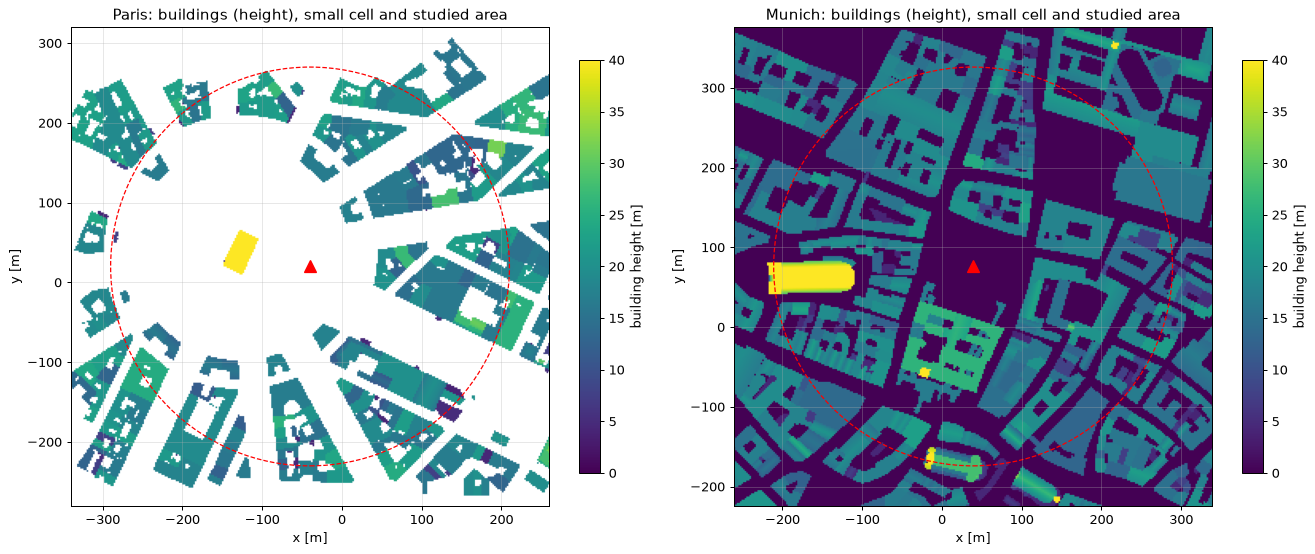

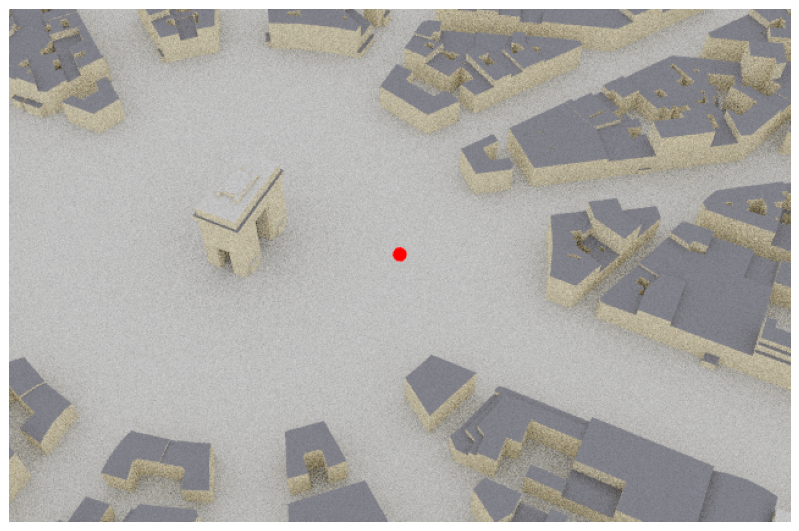

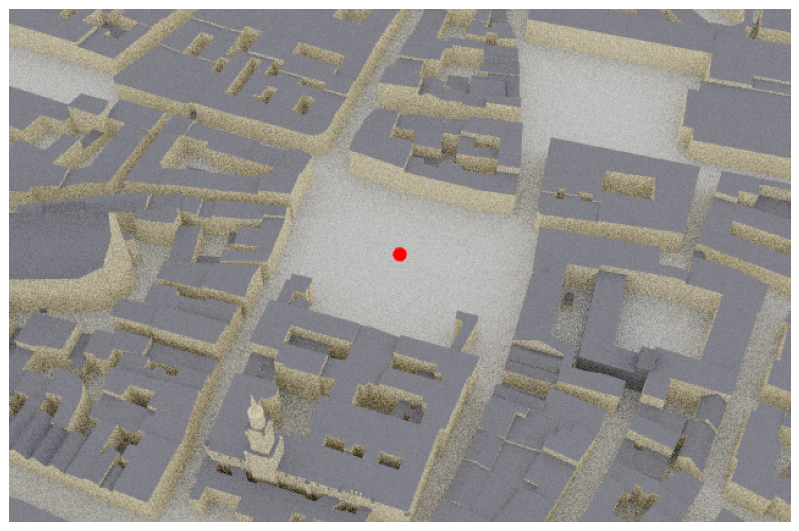

In [3]:
# The two cities seen from above, then in 3D
HEIGHT_MAP_PIXEL = 2.0                                 # side of the pixels of the height map [m]
HEIGHTS = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, city in zip(axes, CITIES):
    scene = load_city(city)
    record(city, "frequency [GHz]", float(scene.frequency.numpy()[0]) / 1e9)   # first row of the table
    HEIGHTS[city] = height_map(scene, pixel=HEIGHT_MAP_PIXEL)   # x and y of the pixel centres, heights [m]
    show_city(ax, city, *HEIGHTS[city])
fig.tight_layout()
plt.show()
for city in CITIES:
    load_city(city).render(camera=city_camera(city), resolution=(640, 420), num_samples=16)

## Exercise 1 - The two environments

For a small cell below the roofs, what matters is how much of the area is open, how high the
buildings are compared with the antenna, and building materials.

**Your code** (ref helpers 1.3, 1.4, 1.5, 2.1): complete `environment(city, xs, ys, heights)`.

It receives the height map of Exercise 0, made of pixels of 2 m × 2 m (`HEIGHT_MAP_PIXEL`). `xs` and
`ys` are the x and y coordinates of the pixel centres, and `heights[i, j]` is the height of the pixel
at (`xs[j]`, `ys[i]`): 0 on a street or a square, the height of the roof on a building. A pixel more
than 2 m high is a building; any other pixel is open ground.

Using only the pixels within 250 m of the TX (the mask `inside`, already computed), the function
returns:
- `open_area`: the percentage of the pixels that are open ground;
- `median_height` and `p90_height`: the median and the 90th percentile of the heights of the
  building pixels;
- `above_tx`: the percentage of the building pixels that are higher than the TX (`TX_HEIGHT`, 10 m).

In [ ]:
# ---------------------------------------------------------------- Exercise 1: the two environments
def environment(city, xs, ys, heights):
    X, Y = np.meshgrid(xs, ys)
    inside = distance_to(X, Y, CITIES[city]["site"]) <= R          # pixels of the studied area
    # open_area: % of the pixels inside that are open ground (2 m high or lower). Building pixels inside
    # (more than 2 m high): median_height, p90_height, and above_tx, the % of them higher than TX_HEIGHT.
    # TODO [Ex 1.1]: compute open_area, median_height, p90_height and above_tx (ref helpers 1.3, 1.4, 1.5, 2.1)
    raise NotImplementedError("Ex 1.1 not completed yet: compute open_area, median_height, p90_height and above_tx (ref helpers 1.3, 1.4, 1.5, 2.1)")
    return open_area, median_height, p90_height, above_tx


for city in CITIES:
    open_area, median_height, p90_height, above_tx = environment(city, *HEIGHTS[city])
    record(city, "open area [%]", open_area)
    record(city, "median building height [m]", median_height)
    record(city, "90th percentile building height [m]", p90_height)
    record(city, "building area above the TX [%]", above_tx)
    print(f"{city}, objects per material:", materials_of(city))
show_results()

**Q1.1** Compare the two environments: what do the cities have in common, and what distinguishes
them?

**Your answer:** _write here_

**Q1.2** Before going on: in which environment (in current settings) you will expect more coverage, more LoS contributions and larger delay spreads?
Why? What else do you expect?

**Your answer:** _write here_

## Exercise 2 - Coverage and line of sight

- **Coverage:** % of the outdoor pixels of the area with $P_R\ge P_{R,\min}$ (each pixel holds the power
  averaged over it).
- **LoS area:** % of the pixels reached by a map with `max_depth=0` (direct path only).
- **LoS probability:** the LoS probability in multiple study areas. Multiple concentric circles are considered as study areas. As reference the 3GPP UMi is considered, in which for $d>18$ m:
  $P_\mathrm{LoS}(d)=\frac{18}{d}+e^{-d/36}\left(1-\frac{18}{d}\right)$.

**Your code** (ref helpers 1.4, 2.3): complete two functions.
- `radio_map(scene, center, ...)` computes the radio map with `RadioMapSolver` and returns it. The map
  is a square of side $2R=500$ m centred on `center`, at the height of the receivers, made of pixels of
  4 m × 4 m; the number of rays, the interactions and the propagation mechanisms come from the
  arguments (the comment in the function lists them).
- `coverage_and_los(prx_dbm, gain_los, area)` returns two percentages values of the pixels of `area`: the
  coverage (pixels with $P_R\ge P_{R,\min}$) and the LoS area (pixels where the LoS map `gain_los` is not
  zero).

In [ ]:
# ---------------------------------------------------------------- parameters
NUM_RAYS = 10**7       # rays of the radio maps
PIXEL_SIZE = 4.0       # side of the pixels of the radio maps [m]
MAX_DEPTH = 5          # maximum number of interactions per path
# ---------------------------------------------------------------- Exercise 2: coverage and line of sight
def radio_map(scene, center, max_depth=MAX_DEPTH, reflection=True, diffraction=True, num_rays=NUM_RAYS,
              scattering=False):
    # A square of side 2 * R centred on center (x, y), at RX_HEIGHT, pixels of PIXEL_SIZE; num_rays,
    # max_depth, reflection (specular), diffraction and scattering (diffuse reflection) as given; LoS
    # on; no refraction; seed=SEED.
    # TODO [Ex 2.1]: return the radio map computed by RadioMapSolver (ref helpers 2.3)
    raise NotImplementedError("Ex 2.1 not completed yet: return the radio map computed by RadioMapSolver (ref helpers 2.3)")


def coverage_and_los(prx_dbm, gain_los, area):
    # coverage: % of the pixels of area with prx_dbm >= THRESHOLD_DBM; los_area: % of the pixels of area
    # where the LoS map gain_los is not zero.
    # TODO [Ex 2.2]: compute coverage and los_area (ref helpers 1.4, 2.3)
    raise NotImplementedError("Ex 2.2 not completed yet: compute coverage and los_area (ref helpers 1.4, 2.3)")
    return coverage, los_area


MAPS = {}
for city in CITIES:
    scene, center = load_city(city), CITIES[city]["site"]
    rm = radio_map(scene, center)
    rm_los = radio_map(scene, center, max_depth=0, diffraction=False)
    area, d2 = outdoor_pixels(scene, rm, center)              # studied area; distance of every pixel
    prx = watt_to_dbm(rm.rss.numpy()[0])
    gain_los = rm_los.path_gain.numpy()[0]
    coverage, los_area = coverage_and_los(prx, gain_los, area)
    MAPS[city] = dict(rm=rm, prx=prx, gain=rm.path_gain.numpy()[0], gain_los=gain_los, area=area, d2=d2)
    record(city, "coverage [%]", coverage)
    record(city, "LoS area [%]", los_area)
show_radio_maps({city: (m["prx"], m["rm"], m["area"]) for city, m in MAPS.items()})

bins = [20, 50, 100, 150, 200, 250]                            # rings for the probability of LoS [m]
los_share = {city: [100 * np.mean(m["gain_los"][m["area"] & (m["d2"] >= lo) & (m["d2"] < hi)] > 0)
                    for lo, hi in zip(bins[:-1], bins[1:])] for city, m in MAPS.items()}
for city, share in los_share.items():
    print(f"{city}: LoS probability in the studied area of radius {bins} m: {np.round(share).astype(int)} %")
print("3GPP UMi reference:",
      np.round(100 * umi_los_probability((np.array(bins[:-1]) + np.array(bins[1:])) / 2)).astype(int), "%")
plot_los_probability(los_share, bins)
show_results()

**Q2.1** Compare the coverage and the LoS area of the two cities. Which expectations of Q1.2 are
confirmed? Explain with the maps.

**Your answer:** _write here_

**Q2.2** Compare the LoS probability of the two cities with UMi. Which city is closer?

**Your answer:** _write here_

**Q2.3** What are the implications of using UMi for Paris and for Munich? Would you use it for both?

**Your answer:** _write here_

## Exercise 3 - Path loss

Log-distance model with shadowing, fitted on the results of Exercise 2. Separated models are provided for LoS and NLoS, following the model:
$$PL_\mathrm{dB}(d)=PL_0+10\,\alpha\log_{10}d+X_\sigma,$$
with $\alpha$ the path-loss exponent and $X_\sigma$ a Gaussian variable in dB of standard deviation
$\sigma$. 3GPP UMi at 3.5 GHz ($d$: 3D distance, up to about 210 m): $\alpha=2.1$, $\sigma=4$ dB in
LoS; $\alpha=3.53$, $\sigma=7.82$ dB in NLoS.
TO CHEEEEEEEEEEEEEEEEEEEK

**Your code** (ref helpers 1.3, 1.7): complete `fit_log_distance(d, pl)`. It receives the
3D distances `d` and the path losses `pl` of the pixels, fits the model $PL_0+10\,\alpha\log_{10}d$ to them
by least squares, and returns $\alpha$, $\sigma$ (the standard deviation of the residuals) and $PL_0$.

In [ ]:
# ---------------------------------------------------------------- Exercise 3: path loss
def fit_log_distance(d, pl):
    # Fit pl = pl0 + 10 * alpha * log10(d) by least squares; sigma: standard deviation of the residuals.
    # TODO [Ex 3.1]: compute alpha, sigma and pl0 (ref helpers 1.3, 1.7)
    raise NotImplementedError("Ex 3.1 not completed yet: compute alpha, sigma and pl0 (ref helpers 1.3, 1.7)")
    return alpha, sigma, pl0


if not MAPS:
    raise RuntimeError("Exercise 3 uses the radio maps of Exercise 2: complete and run Exercise 2 first.")
PL_DATA = {}
for city, m in MAPS.items():
    d3 = np.hypot(m["d2"], TX_HEIGHT - RX_HEIGHT)              # 3D distance of every pixel [m]
    has_power, los = m["gain"] > 0, m["gain_los"] > 0
    fits = {}
    for label, pixels in (("LoS", m["area"] & has_power & los), ("NLoS", m["area"] & has_power & ~los)):
        pl = -db(m["gain"][pixels])
        fits[label] = fit_log_distance(d3[pixels], pl)
        record(city, f"alpha {label}", fits[label][0])
        record(city, f"sigma {label} [dB]", fits[label][1])
        umi = umi_path_loss(d3[pixels], 3.5, los=(label == "LoS"))
        record(city, f"median PL - UMi, {label} [dB]", np.median(pl - umi))
    record(city, "NLoS area without power [%]", 100 * np.mean(~has_power[m["area"] & ~los]))
    pixels = m["area"] & has_power
    PL_DATA[city] = dict(d=d3[pixels], pl=-db(m["gain"][pixels]), los=los[pixels], fits=fits)
plot_path_loss(PL_DATA)
show_results()

**Q3.1** In LoS, compare $\alpha$ and $\sigma$ with free space ($\alpha=2$) and UMi. Why is $\alpha$ close
to 2, and $\sigma$ so small? Use the results of your simulations to answer.

**Your answer:** _write here_

**Q3.2** In NLoS, does the obtained model fits correctly each city? Why the UMi models does not correctly fit? What the 3GPP UMi assume that the ray tracer does not show?

**Your answer:** _write here_

**Q3.3** Look at the scatter plots of the path loss computed by the ray tracer: how do they differ
between Paris and Munich, and why?

**Your answer:** _write here_

## Exercise 4 - Wideband channel

The radio maps used so far give only the power of each pixel: a narrowband prediction. For a
wideband signal, the arrival times of the paths matter too. Path $i$ reaches a receiver with a
complex amplitude $a_i$ after a delay $\tau_i$; the RMS delay spread $\tau_\mathrm{rms}$ measures how
widely the power is spread in time around the mean delay $\bar\tau$:
$$\bar\tau=\frac{\sum_i|a_i|^2\tau_i}{\sum_i|a_i|^2},\qquad
\tau_\mathrm{rms}=\sqrt{\frac{\sum_i|a_i|^2\tau_i^2}{\sum_i|a_i|^2}-\bar\tau^2}.$$
The coherence bandwidth $B_C$ is the band over which the channel stays roughly flat: a signal wider
than $B_C$ is distorted. The larger the delay spread, the smaller $B_C$. This lab estimates $B_C$ with
the rule of thumb $B_C\approx1/(5\tau_\mathrm{rms})$: an order of magnitude, not an exact relation.
For comparison, 3GPP UMi gives median delay spreads of 40 ns in LoS and 97 ns in NLoS at 3.5 GHz.

To get the paths, the code below places 400 receivers at random in the studied area (outdoors, 20 to
250 m from the TX) and computes their paths with `PathSolver`. The code then plots the CDF of
$\tau_\mathrm{rms}$ in LoS and in NLoS for each city, with the UMi medians as reference lines, and adds
the medians, $B_C$ and the shares of receivers in LoS and without paths to the table. The medians
change by a few % between runs and between computers: only larger differences are meaningful.
The last part of the exercise checks how many receivers are needed for reliable curves and medians.

**Your code** (ref helpers 1.6, 2.4): complete two functions.
- `channel_paths(scene, ...)` returns the paths from the TX to all the receivers of the scene, computed
  with `PathSolver`: the number of interactions and the mechanisms come from the arguments (the
  comment in the function lists them and the other settings).
- `delay_spread(a, tau, valid)` receives three arrays of shape [receivers, paths]: the complex
  amplitudes $a_i$, the delays $\tau_i$ in seconds, and `valid`, True where a path exists. Receivers
  have different numbers of paths, so the arrays also hold empty entries, where `valid` is False,
  $a_i=0$ and $\tau_i$ is NaN (not a number). The function returns the $\tau_\mathrm{rms}$ of every
  receiver, in seconds, computed with the formula above from its valid paths only, and NaN for the
  receivers without paths.

In [ ]:
# ---------------------------------------------------------------- Exercise 4: wideband channel
NUM_RECEIVERS = 400


def channel_paths(scene, max_depth=MAX_DEPTH, reflection=True, diffraction=True, scattering=False):
    # Up to max_depth interactions; LoS on; reflection (specular), diffraction and scattering (diffuse
    # reflection) as given; no refraction; 10**6 rays; at most 10**7 path candidates
    # (max_num_paths_per_src); seed=SEED.
    # TODO [Ex 4.1]: return the paths computed by PathSolver (ref helpers 2.4)
    raise NotImplementedError("Ex 4.1 not completed yet: return the paths computed by PathSolver (ref helpers 2.4)")


def delay_spread(a, tau, valid):
    tau_rms = np.full(len(a), np.nan)                          # NaN for the receivers without paths
    # For every receiver k with at least one valid path: tau_rms[k] from the powers and the delays of
    # its valid paths.
    # TODO [Ex 4.2]: fill tau_rms (ref helpers 1.6, 2.4)
    raise NotImplementedError("Ex 4.2 not completed yet: fill tau_rms (ref helpers 1.6, 2.4)")
    return tau_rms


DS = {}
for city in CITIES:
    scene = load_city(city)
    add_random_receivers(scene, CITIES[city]["site"], n=NUM_RECEIVERS)
    a, tau, valid, los = path_arrays(channel_paths(scene))
    tau_rms, has_path = delay_spread(a, tau, valid), valid.any(axis=1)
    DS[city] = dict(tau_rms=tau_rms, los=los, nlos=~los & has_path)
    record(city, "receivers in LoS [%]", 100 * np.mean(los))
    record(city, "receivers without paths [%]", 100 * np.mean(~has_path))
    record(city, "median rms ds LoS [ns]", 1e9 * np.nanmedian(tau_rms[los]))
    record(city, "median rms ds NLoS [ns]", 1e9 * np.nanmedian(tau_rms[~los & has_path]))
    record(city, "B_C of the NLoS median [MHz]", 1e-6 / (5 * np.nanmedian(tau_rms[~los & has_path])))
plot_cdf({f"{city} {label}": 1e9 * DS[city]["tau_rms"][DS[city][key]] for city in CITIES
          for label, key in (("LoS", "los"), ("NLoS", "nlos"))},
         "RMS delay spread [ns]", references={"UMi median LoS": 40.0, "UMi median NLoS": 97.0})
show_results()

**Q4.1** Compare the four CDFs of $\tau_\mathrm{rms}$ (Paris and Munich, in LoS and in NLoS): why do
they differ so much? What can you already infer from these curves alone? Finally, which of these
scenarios is the most likely to support a signal with a large bandwidth?

**Your answer:** _write here_

**Q4.2** Compare the median delay spreads with the UMi medians: why are the medians of both cities
larger?

**Your answer:** _write here_

**Q4.3** Many receivers in Munich get no path: is the cause the city, the ray tracer, or both?
Which mechanisms does this simulation leave out?

**Your answer:** _write here_

**How many receivers?** The curves above come from 400 receivers placed at random. The code below
draws the same CDFs from the first N of these receivers, for each N in `NUM_PLACED`, and prints the
medians. In the legend, the number in brackets is how many of the receivers fall in that scenario (LoS
or NLoS).

In [ ]:
# ---------------------------------------------------------------- Exercise 4: how many receivers?
NUM_PLACED = [25, 100, 400, 1000, 5000, 10000]   # the first N receivers: as if only N had been placed at random
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
scenarios = [(city, label, key) for city in CITIES for label, key in (("LoS", "los"), ("NLoS", "nlos"))]
for ax, (city, label, key) in zip(axes.flat, scenarios):
    tau, in_scenario = 1e9 * DS[city]["tau_rms"], DS[city][key]
    curves = {f"{n} receivers": tau[:n][in_scenario[:n]] for n in NUM_PLACED}
    plot_cdf(curves, "RMS delay spread [ns]", ax=ax, title=f"{city} {label}")
    print(f"{city} {label}, median [ns]: "
          + ", ".join(f"{n} receivers {np.nanmedian(v):.0f}" for n, v in zip(NUM_PLACED, curves.values())))
fig.tight_layout()
plt.show()

**Q4.4** How many receivers should you place to get a reliable CDF and median in each scenario? In
general, is this number the same for all four scenarios?

**Your answer:** _write here_

**Q4.5** Why is the number of receivers important, and what are the implications of setting it
properly? Is there a trade-off?

**Your answer:** _write here_

## Exercise 5 - How many rays?

The radio maps of Exercises 2 and 3 use $10^7$ rays per city. A ray launcher finds a path only if one
of its rays follows it: with fewer rays it misses paths, above all far from the TX and after several
interactions, but it runs faster. As the number of receivers in Exercise 4, the number of rays is a
trade-off between accuracy and time.

The code below recomputes the coverage of Exercise 2 in both cities with $10^5$, $10^6$ and $10^7$
rays, and prints the coverage and the run time of each map. The physical inputs (frequency, materials,
rough walls, height of the small cell) are the ones to test in Exercise 6.

In [ ]:
# ---------------------------------------------------------------- Exercise 5: how many rays?
for city in CITIES:
    scene, center = load_city(city), CITIES[city]["site"]
    for num_rays, label in ((10**5, "10^5"), (10**6, "10^6"), (10**7, "10^7")):
        start = time.time()
        rm = radio_map(scene, center, num_rays=num_rays)
        area, _ = outdoor_pixels(scene, rm, center)
        coverage = 100 * np.mean(watt_to_dbm(rm.rss.numpy()[0])[area] >= THRESHOLD_DBM)
        print(f"{city}: {label} rays, coverage {coverage:.1f} %, run time {time.time() - start:.1f} s")
        if num_rays < NUM_RAYS:
            record(city, f"coverage, {label} rays [%]", coverage)

**Q5.1** How much coverage does each city lose with $10^6$ and with $10^5$ rays, and how much faster
is each map? Why does one city lose more? How would you choose the number of rays?

**Your answer:** _write here_

## Exercise 6 - From propagation to planning

**Goal:** an end-to-end analysis of a city. Understand how the radio waves propagate in it, with all the
inputs met so far, then use what you learn to plan its small cells, and show the results in the final
presentation.

You have full control. Set the parameters in the next code cell and run the three code cells below it
(1-3 min on a central processing unit, CPU); change the parameters and run them again. The default values are those of
Exercises 2-4, with a second small cell as an example of the lists (one entry per small cell).
- `CITY`: "Paris" or "Munich", or "Florence", another city of Sionna RT.
- Propagation: `FREQUENCY_GHZ`, the carrier frequency (1 to 40 GHz, where the ITU models of the
  materials hold); `BUILDINGS`, "default" (the materials of the
  scene) or one ITU material for all the buildings ("concrete", "brick", "glass", "metal", "wood",
  "marble", ...); `SCATTERING`, the roughness of the walls, from 0 (smooth) to 1; `INTERACTIONS`, the
  maximum number of interactions per path; `REFLECTION` and `DIFFRACTION`, to switch these mechanisms on
  or off.
- Small cells: `N_TX`, how many; `positions`, their positions (x, y, z) in metres (the coverage map shows
  x and y; at z = 10 m a small cell is below the roofs); `TX_power_dBm`, their transmit powers in dBm.
- `RX_POSITION`: the point (x, y) where the last code cell shows the channel impulse response (CIR) and
  the frequency response; `BANDWIDTH_MHZ`: the band of the frequency response around the carrier.

The three code cells show:
1. **Coverage:** the map of the received power, each pixel served by its strongest small cell (its
   **best server**), the coverage and the LoS area of the studied area (outdoors, 20 to 250 m from the
   square), the CDF of the received power over that area and, with several small cells, the share of
   the covered pixels with a signal-to-interference ratio (SIR) below 6 dB and the CDF of the SIR. The SIR of a pixel is the power of its best server divided by the sum of the
   powers of the other small cells, which use the same carrier.
2. **Channel of the users:** 400 receivers placed at random as in Exercise 4, each served by its best
   server, with your functions of Exercise 4: the share of receivers in LoS and without paths, the
   median delay spread, $B_C$, and the CDFs of the delay spread. To save memory, these paths ignore the
   roughness of the walls.
3. **CIR and frequency response:** the paths from each small cell to `RX_POSITION`, as received power
   against delay, one colour per mechanism (LoS, reflection, diffraction, scattering), with the share of
   the power of each one; and the frequency response $|H(f)|^2$, the Fourier transform of the CIR,
   with the coherence bandwidth $B_C\approx1/(5\tau_\mathrm{rms})$ of each small cell as a shaded band.

In [ ]:
# ---------------------------------------------------------------- parameters: change these
CITY = "Munich"                              # "Paris", "Munich" or "Florence"
# propagation
FREQUENCY_GHZ = 3.5                          # carrier frequency [GHz], 1 to 40, e.g. 1.8, 3.5 or 28
BUILDINGS = "default"                        # "default" or one ITU material, e.g. "glass" or "metal"
SCATTERING = 0.0                             # roughness of the walls: 0 (smooth) to 1 (rough)
INTERACTIONS = 5                             # maximum number of interactions per path
REFLECTION = True                            # specular reflections: True or False
DIFFRACTION = True                           # diffraction on the edges of the buildings: True or False
# small cells: one entry per small cell in each list
N_TX = 2                                     # number of small cells
positions = [(39, 76, 10), (-60, 171, 10)]   # (x, y, z) of each small cell [m]
TX_power_dBm = [30, 30]                      # transmit power of each small cell [dBm]
RX_POSITION = (146, 86)                      # (x, y) of the receiver of the CIR [m]
BANDWIDTH_MHZ = 20                           # band of the frequency response around the carrier [MHz]

In [ ]:
# ---------------------------------------------------------------- Exercise 6: coverage
assert len(positions) == N_TX and len(TX_power_dBm) == N_TX, "give one position and one power per small cell"
center = ALL_CITIES[CITY]["site"]                    # centre of the studied area: the square


def city_scene(tx_positions, tx_powers, rough=True):
    # The city at FREQUENCY_GHZ, with the chosen materials and walls (smooth if rough=False) and these small cells
    scene = load_city(CITY, frequency_ghz=FREQUENCY_GHZ)
    if BUILDINGS != "default":                       # one ITU material for all the buildings
        material = ITURadioMaterial(f"buildings-{BUILDINGS}", BUILDINGS, thickness=0.1)
        for obj in building_objects(scene, CITY):
            obj.radio_material = material
    for obj in building_objects(scene, CITY):        # roughness of the walls
        obj.radio_material.scattering_coefficient = SCATTERING if rough else 0.0
    set_small_cells(scene, tx_positions, tx_powers)
    return scene


scene = city_scene(positions, TX_power_dBm)
rm = radio_map(scene, center, max_depth=INTERACTIONS, reflection=REFLECTION, diffraction=DIFFRACTION,
               scattering=SCATTERING > 0)            # one map per small cell: rm.rss[k] [W]
rm_los = radio_map(scene, center, max_depth=0)       # direct paths only
area, _ = outdoor_pixels(scene, rm, center)
prx = watt_to_dbm(rm.rss.numpy()).max(axis=0)        # power of the best server in each pixel [dBm]
covered = area & (prx >= THRESHOLD_DBM)
print(f"{CITY}, {N_TX} small cell(s): coverage {100 * covered.sum() / area.sum():.1f} %, "
      f"LoS area {100 * np.mean(rm_los.rss.numpy().max(axis=0)[area] > 0):.1f} %")
show_radio_maps({CITY: (prx, rm, area)}, title="best server, P_R [dBm]", sites={CITY: positions})
plot_cdf({f"{CITY}, {N_TX} small cell(s)": np.maximum(prx[area], -160)},   # pixels without power at -160 dBm
         "P_R of the best server [dBm]", references={"P_R,min": THRESHOLD_DBM})
if N_TX > 1:
    sir = sir_db(rm.rss.numpy())[covered]           # SIR of the covered pixels [dB]
    print(f"covered pixels with SIR < 6 dB: {100 * np.mean(sir < 6):.1f} %")
    plot_cdf({"covered pixels": sir}, "SIR [dB]", references={"6 dB": 6.0})

In [ ]:
# ---------------------------------------------------------------- Exercise 6: channel of the users
points = add_random_receivers(load_city(CITY), center, n=NUM_RECEIVERS)   # 400 random receivers, as in Exercise 4
server = best_server(rm, points, positions)          # the small cell that serves each receiver
tau_rms, los = np.full(NUM_RECEIVERS, np.nan), np.zeros(NUM_RECEIVERS, bool)
for k in range(N_TX):                                # each small cell with the receivers it serves
    served = server == k
    if served.any():
        scene_k = city_scene([positions[k]], [TX_power_dBm[k]], rough=False)
        add_receivers(scene_k, points[served])
        paths = channel_paths(scene_k, max_depth=INTERACTIONS, reflection=REFLECTION, diffraction=DIFFRACTION)
        a, tau, valid, los_k = path_arrays(paths)
        tau_rms[served], los[served] = delay_spread(a, tau, valid), los_k
nlos = ~los & ~np.isnan(tau_rms)
print(f"receivers in LoS {100 * np.mean(los):.0f} %, without paths {100 * np.mean(np.isnan(tau_rms)):.0f} %")
print(f"median delay spread: LoS {1e9 * np.nanmedian(tau_rms[los]):.0f} ns, NLoS {1e9 * np.nanmedian(tau_rms[nlos]):.0f} ns; "
      f"B_C of the NLoS median {1e-6 / (5 * np.nanmedian(tau_rms[nlos])):.1f} MHz")
plot_cdf({"LoS": 1e9 * tau_rms[los], "NLoS": 1e9 * tau_rms[nlos]}, "RMS delay spread [ns]")

In [ ]:
# ---------------------------------------------------------------- Exercise 6: CIR and frequency response at RX_POSITION
fig, (ax_cir, ax_f) = plt.subplots(1, 2, figsize=(15, 4.2))
for k in range(N_TX):                                # the paths from each small cell to RX_POSITION
    scene_k = city_scene([positions[k]], [TX_power_dBm[k]])
    add_receivers(scene_k, np.array([RX_POSITION]))
    paths = channel_paths(scene_k, max_depth=INTERACTIONS, reflection=REFLECTION, diffraction=DIFFRACTION,
                          scattering=SCATTERING > 0)
    plot_cir(ax_cir, paths, TX_power_dBm[k], k)      # one colour per mechanism
    a, tau, valid, _ = path_arrays(paths)
    b_c = 1 / (5 * delay_spread(a, tau, valid)[0])   # coherence bandwidth [Hz], with your function of Exercise 4
    plot_frequency_response(ax_f, paths, TX_power_dBm[k], k, BANDWIDTH_MHZ, b_c)
ax_cir.set_title(f"{CITY}: CIR at {RX_POSITION}")
ax_f.set_title("frequency response (shaded: the coherence bandwidth)")
ax_cir.legend(fontsize=8)
ax_f.legend(fontsize=8)
plt.show()

**What to test.** There are no questions here: run an end-to-end analysis, from the propagation to the
plan, and show its results in the final presentation. Some ideas, which are also the checks of
robustness of your results:
- **Mechanisms:** switch `REFLECTION` and `DIFFRACTION` off one at a time and reduce `INTERACTIONS`:
  which mechanisms carry the power, and where?
- **Materials:** compare, e.g., "metal", "glass" and "concrete" buildings with the default ones.
- **Frequency:** compare 1.8, 3.5 and 28 GHz.
- **Rough walls:** set `SCATTERING` to 0.3 or more.
- **Height:** a small cell below the roofs (z = 10 m) and one above them (z = 30 m).
- **Coherence bandwidth:** compare the frequency response with the shaded $B_C$: over which band is the
  channel roughly flat, and how does it change with the materials, the frequency or a closer small cell?
- **Planning:** one well-placed small cell or several; more power or more small cells; how much they
  interfere (SIR); how the channel of the users changes (LoS, delay spread, CIR).

For each effect, look at the coverage, the delay spread and the CIR, and explain it with the physics
(reflection coefficient, diffraction, wavelength). In the presentation, show the propagation in each city
and the plan you propose, with the numbers and figures that support it.

## Summary of the results

The table collects the numbers of Exercises 1-5: use it, with your figures and your analysis of
Exercise 6, to prepare the presentation.

In [ ]:
show_results()

## The presentation (next session)

5 minutes plus 1.5 minutes of questions per group; each of the two members presents a part. About five
slides: the cities and your expectations; coverage, LoS and path loss against UMi; delay spread and
robustness; your end-to-end analysis of Exercise 6, from the propagation to the plan of each city; the
main differences.

# How to submit

1. Complete all the TODO cells and the answers, then save (*File → Save*) without restarting the
   kernel: the outputs are your evidence.
2. Rename the file `lab3_<name_surname>_<name_surname>.ipynb` (in the Visual Studio
   Code (VS Code) Explorer: right-click → *Rename*; to copy it from the virtual machine:
   right-click → *Download...*).
3. Before the next session, email the notebook and your slides, in Portable Document Format (PDF), to
   Matteo Bernabe, [matteo.bernabe@iteam.upv.es](mailto:matteo.bernabe@iteam.upv.es), with the
   subject `Lab 3 Sionna - <name_surname>, <name_surname>`.